In [3]:

import sys
import numpy as np
import pandas as pd

print("Python executable:", sys.executable)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Environment configured successfully!")


Python executable: c:\Users\Awais\OneDrive\Documents\customers-like-you\.venv\Scripts\python.exe
NumPy version: 2.5.3
Pandas version: 3.0.6
Environment configured successfully!


In [8]:
from pathlib import Path
import pandas as pd

# Location of our retail dataset
file_path = Path("../data/raw/online_retail_II.xlsx")

# Check whether Python can find the file
print("file found:", file_path.exists)

#load both sheets
sheets = pd.read_excel(file_path, sheet_name= None)

#Display worksheet names and rows counts
for name, sheet in sheets.items():
    print(f"{name}: {len(sheet):,} rows")

#combine the two datasets
df= pd.concat(sheets.values(), ignore_index=True)

print("\nTotal rows:", len(df))
print("Total columns:", df.shape[1])



file found: <bound method Path.exists of WindowsPath('../data/raw/online_retail_II.xlsx')>
Year 2009-2010: 525,461 rows
Year 2010-2011: 541,910 rows

Total rows: 1067371
Total columns: 8


In [9]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [10]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()


Column names:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[us]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 65.1+ MB


In [16]:

# Check missing values in each column
missing_report = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

display(missing_report)


,Missing Values,Missing Percentage
Invoice,0,0.00
StockCode,0,0.00
Description,4382,0.41
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Customer ID,243007,22.77
Country,0,0.00


In [17]:

# Confirm the exact column names before executing
print("Non-positive quantities:",
      (df["Quantity"] <= 0).sum())

print("Non-positive prices:",
      (df["Price"] <= 0).sum())

print("Cancellation invoice lines:",
      df["Invoice"].astype(str)
        .str.startswith("C").sum())


Non-positive quantities: 22950
Non-positive prices: 6207
Cancellation invoice lines: 19494


In [18]:

print("Earliest transaction:", df["InvoiceDate"].min())
print("Latest transaction:", df["InvoiceDate"].max())


Earliest transaction: 2009-12-01 07:45:00
Latest transaction: 2011-12-09 12:50:00


DE2 - Clean the dataset

In [19]:
#creating the working copy
clean_df = df.copy()

cleaning_log = []

def record_removal(rule, before_count, after_count):
    cleaning_log.append({
        "Cleaning Rule": rule,
        "Rows Removed": before_count - after_count,
        "Rows Remaining": after_count
    })

print("Starting records:", len(clean_df))

Starting records: 1067371


In [20]:
#Remove cancelled invoices
before_count = len(clean_df)

# Identify invoices starting with C
cancelled = (
    clean_df["Invoice"]
    .astype(str)
    .str.upper()
    .str.startswith("C")
)

# Keep only non-cancelled transactions
clean_df = clean_df.loc[~cancelled].copy()

# Record the number of removed rows
record_removal(
    "Cancelled invoices",
    before_count,
    len(clean_df)
)

print("Records after removing cancellations:", len(clean_df))
print("Cancellation lines removed:", before_count - len(clean_df))

Records after removing cancellations: 1047877
Cancellation lines removed: 19494


In [21]:
pd.DataFrame(cleaning_log)

,Cleaning Rule,Rows Removed,Rows Remaining
0,Cancelled invoices,19494,1047877


In [22]:
#Remove non-positive quantities
# Store the number of records before filtering
before_count = len(clean_df)

# Keep transactions where the customer bought at least one unit
clean_df = clean_df.loc[
    clean_df["Quantity"] > 0
].copy()

# Record this step in our cleaning log
record_removal(
    "Non-positive quantities",
    before_count,
    len(clean_df)
)

print("Records before:", before_count)
print("Records after:", len(clean_df))
print("Rows removed:", before_count - len(clean_df))

Records before: 1047877
Records after: 1044420
Rows removed: 3457


In [23]:
display(pd.DataFrame(cleaning_log))

,Cleaning Rule,Rows Removed,Rows Remaining
0,Cancelled invoices,19494,1047877
1,Non-positive quantities,3457,1044420


In [24]:
#Remove non-positive prices
# Store the record count before applying the filter
before_count = len(clean_df)

# Keep transactions with a valid positive unit price
clean_df = clean_df.loc[
    clean_df["Price"] > 0
].copy()

# Record the cleaning operation
record_removal(
    "Non-positive prices",
    before_count,
    len(clean_df)
)

print("Records before:", before_count)
print("Records after:", len(clean_df))
print("Rows removed:", before_count - len(clean_df))

Records before: 1044420
Records after: 1041670
Rows removed: 2750


In [25]:
display(pd.DataFrame(cleaning_log))

print(
    "Remaining non-positive prices:",
    (clean_df["Price"] <= 0).sum()
)

,Cleaning Rule,Rows Removed,Rows Remaining
0,Cancelled invoices,19494,1047877
1,Non-positive quantities,3457,1044420
2,Non-positive prices,2750,1041670


Remaining non-positive prices: 0


In [26]:
#Remove missing Customer IDs
# Record the number of rows before filtering
before_count = len(clean_df)

# Keep only transactions with a valid Customer ID
clean_df = clean_df.loc[
    clean_df["Customer ID"].notna()
].copy()

# Update the cleaning log
record_removal(
    "Missing Customer IDs",
    before_count,
    len(clean_df)
)

print("Records before:", before_count)
print("Records after:", len(clean_df))
print("Rows removed:", before_count - len(clean_df))

Records before: 1041670
Records after: 805549
Rows removed: 236121


In [ ]:
#Verify the cleaning
print(
    "Missing Customer IDs remaining:",
    clean_df["Customer ID"].isna().sum()
)

print(
    "Unique customers:",
    clean_df["Customer ID"].nunique()
)

display(pd.DataFrame(cleaning_log))

Missing Customer IDs remaining: 0
Unique customers: 5878


,Cleaning Rule,Rows Removed,Rows Remaining
0,Cancelled invoices,19494,1047877
1,Non-positive quantities,3457,1044420
2,Non-positive prices,2750,1041670
3,Missing Customer IDs,236121,805549


Cleaning Decision 4 — Missing Customer IDs
Transactions without Customer IDs were removed because the recommendation system requires customer-level purchasing histories. Retaining these transactions would make it impossible to correctly associate purchases with individual customers. Only transactions with valid customer identifiers are used to construct the customer-product matrix.

In [28]:
#Examine unusual StockCodes
# Count transactions for codes containing non-digit characters
stock_codes = clean_df["StockCode"].astype(str).str.strip().str.upper()

unusual_codes = clean_df.loc[
    ~stock_codes.str.fullmatch(r"\d{5}[A-Z]?")
]

print("Rows with unusual StockCodes:", len(unusual_codes))

display(
    unusual_codes.groupby(["StockCode", "Description"])
    .size()
    .reset_index(name="Transaction Count")
    .sort_values("Transaction Count", ascending=False)
    .head(25)
)

Rows with unusual StockCodes: 3990


,StockCode,Description,Transaction Count
13,POST,POSTAGE,1838
0,15056BL,EDWARDIAN PARASOL BLACK,838
11,M,Manual,709
8,C2,CARRIAGE,253
2,79323LP,LIGHT PINK CHERRY LIGHTS,159
1,79323GR,GREEN CHERRY LIGHTS,76
7,BANK CHARGES,Bank Charges,30
3,ADJUST,Adjustment by john on 26/01/2010 16,18
12,PADS,PADS TO MATCH ALL CUSHIONS,17
10,DOT,DOTCOM POSTAGE,16


In [29]:
#Remove known non-product entries
# Known service and adjustment codes
excluded_codes = {
    "POST", "POSTAGE", "M", "D",
    "DOT", "BANK CHARGES",
    "C2", "ADJUST", "ADJUST2", "CRUK"
}

before_count = len(clean_df)

# Keep transactions whose StockCode is not excluded
clean_df = clean_df.loc[
    ~clean_df["StockCode"]
    .astype(str)
    .str.strip()
    .str.upper()
    .isin(excluded_codes)
].copy()

record_removal(
    "Non-product StockCodes",
    before_count,
    len(clean_df)
)

print("Records before:", before_count)
print("Records after:", len(clean_df))
print("Rows removed:", before_count - len(clean_df))

Records before: 805549
Records after: 802661
Rows removed: 2888


In [30]:
#verifying cleaning result
print(
    "Excluded StockCodes remaining:",
    clean_df["StockCode"]
    .astype(str)
    .str.strip()
    .str.upper()
    .isin(excluded_codes)
    .sum()
)

print("Unique products remaining:", clean_df["StockCode"].nunique())

display(pd.DataFrame(cleaning_log))

Excluded StockCodes remaining: 0
Unique products remaining: 4623


,Cleaning Rule,Rows Removed,Rows Remaining
0,Cancelled invoices,19494,1047877
1,Non-positive quantities,3457,1044420
2,Non-positive prices,2750,1041670
3,Missing Customer IDs,236121,805549
4,Non-product StockCodes,2888,802661


Cleaning Decision 5 — Non-product StockCodes
Certain StockCodes represent shipping charges, manual adjustments, discounts, or other non-merchandise entries. These were excluded because the recommendation system should suggest actual retail products rather than transaction-related services. Valid products with unusual StockCode formats were retained unless they could be identified as non-product entries.

In [31]:
#checking missing descriptions
missing_description = (
    clean_df["Description"].isna()
    | clean_df["Description"].astype(str).str.strip().eq("")
)

print("Missing descriptions remaining:", missing_description.sum())
print("Rows before final cleaning:", len(clean_df))

Missing descriptions remaining: 0
Rows before final cleaning: 802661


In [32]:
#Remove rows with missing descriptions
before_count = len(clean_df)

clean_df = clean_df.loc[
    ~missing_description
].copy()

record_removal(
    "Missing product descriptions",
    before_count,
    len(clean_df)
)

print("Rows removed:", before_count - len(clean_df))
print("Final cleaned records:", len(clean_df))

Rows removed: 0
Final cleaned records: 802661


In [33]:
#validate the cleaned dataset
assert clean_df["Customer ID"].notna().all()
assert clean_df["Description"].notna().all()
assert (clean_df["Quantity"] > 0).all()
assert (clean_df["Price"] > 0).all()
assert not clean_df["Invoice"].astype(str).str.upper().str.startswith("C").any()

print("All cleaning validation checks passed!")

display(pd.DataFrame(cleaning_log))

print("\nFinal dataset shape:", clean_df.shape)
print("Unique customers:", clean_df["Customer ID"].nunique())
print("Unique products:", clean_df["StockCode"].nunique())

All cleaning validation checks passed!


,Cleaning Rule,Rows Removed,Rows Remaining
0,Cancelled invoices,19494,1047877
1,Non-positive quantities,3457,1044420
2,Non-positive prices,2750,1041670
3,Missing Customer IDs,236121,805549
4,Non-product StockCodes,2888,802661
5,Missing product descriptions,0,802661



Final dataset shape: (802661, 8)
Unique customers: 5852
Unique products: 4623


Cleaning Decision 6 — Missing Product Descriptions: Records without usable product descriptions were excluded so recommendations and customer segment summaries can be interpreted using recognizable product names. The number removed was recorded separately to avoid double-counting earlier exclusions.

In [ ]:
#saving cleaned dataset
from pathlib import Path

# Locate the project root
project_dir = Path.cwd()

if project_dir.name == "notebook":
    project_dir = project_dir.parent

output_dir = project_dir / "outputs"

output_dir.mkdir(parents=True, exist_ok=True)

# Save cleaned dataset
clean_df.to_pickle(
    output_dir / "cleaned_transactions.pkl"
)

# Save cleaning log
pd.DataFrame(cleaning_log).to_csv(
    output_dir / "cleaning_log.csv",
    index=False
)

print("Files saved successfully!")
print("Saved location:", output_dir.resolve())

Files saved successfully!
Saved location: C:\Users\Awais\OneDrive\Documents\customers-like-you\outputs


DE3 — Time-Based Data Splitting
The dataset is divided chronologically, with the final two months reserved for testing. This simulates a real-world recommendation system trained on historical purchases and evaluated on future buying behavior.

In [35]:
# Ensure transaction dates are datetime values
clean_df["InvoiceDate"] = pd.to_datetime(
    clean_df["InvoiceDate"]
)

# Use the latest transaction to determine the cutoff
last_transaction = clean_df["InvoiceDate"].max()

cutoff_date = last_transaction - pd.DateOffset(months=2)

print("Latest transaction:", last_transaction)
print("Training cutoff:", cutoff_date)

Latest transaction: 2011-12-09 12:50:00
Training cutoff: 2011-10-09 12:50:00


In [36]:
#Separate training and testing transactions
# Transactions before the cutoff are training data
train_df = clean_df.loc[
    clean_df["InvoiceDate"] < cutoff_date
].copy()

# Transactions on or after the cutoff are test data
test_df = clean_df.loc[
    clean_df["InvoiceDate"] >= cutoff_date
].copy()

print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))

print("Total rows:", len(train_df) + len(test_df))

assert len(train_df) + len(test_df) == len(clean_df)
assert train_df["InvoiceDate"].max() < cutoff_date
assert test_df["InvoiceDate"].min() >= cutoff_date

Training rows: 684098
Testing rows: 118563
Total rows: 802661


In [37]:
# Unique customer-product relationships in training
previous_purchases = (
    train_df[["Customer ID", "StockCode"]]
    .drop_duplicates()
    .assign(bought_before=True)
)

# Unique customer-product relationships in testing
future_purchases = (
    test_df[["Customer ID", "StockCode"]]
    .drop_duplicates()
)

# Keep only test customers who appeared in training
known_customers = set(train_df["Customer ID"].unique())

future_purchases = future_purchases.loc[
    future_purchases["Customer ID"].isin(known_customers)
].copy()

# Check which future customer-product pairs were already purchased
purchase_check = future_purchases.merge(
    previous_purchases,
    on=["Customer ID", "StockCode"],
    how="left"
)

# Retain only genuinely new customer-product purchases
heldout_df = purchase_check.loc[
    purchase_check["bought_before"].isna(),
    ["Customer ID", "StockCode"]
].copy()

print("Test customer-product pairs:", len(future_purchases))
print("Held-out new purchase pairs:", len(heldout_df))
print("Customers eligible for evaluation:",
      heldout_df["Customer ID"].nunique())

Test customer-product pairs: 81189
Held-out new purchase pairs: 49423
Customers eligible for evaluation: 1930


DE4 — Customer-Product Interaction Matrix

In [38]:
# Counting the number of distinct customers purchasing each product
product_popularity = (
    train_df.groupby("StockCode")["Customer ID"]
    .nunique()
)

# products purchased by at least 10 different customers
eligible_products = product_popularity[
    product_popularity >= 10
].index

# Applying the product filter only to training data
matrix_train = train_df.loc[
    train_df["StockCode"].isin(eligible_products),
    ["Customer ID", "StockCode"]
].drop_duplicates().copy()

print("Training customers:", train_df["Customer ID"].nunique())
print("Products meeting minimum popularity:", len(eligible_products))
print("Unique customer-product interactions:", len(matrix_train))

Training customers: 5474
Products meeting minimum popularity: 3688
Unique customer-product interactions: 413942


In [39]:
# Mapping original customer IDs to matrix row positions
customer_ids = train_df["Customer ID"].drop_duplicates()

customer_index = {
    customer_id: position
    for position, customer_id in enumerate(customer_ids)
}

# Mapping eligible products to matrix column positions
product_index = {
    product_code: position
    for position, product_code in enumerate(eligible_products)
}

print("Customer indices:", len(customer_index))
print("Product indices:", len(product_index))

Customer indices: 5474
Product indices: 3688


In [ ]:
#contructing a sparse matrix
import numpy as np
from scipy.sparse import csr_matrix

# Convert customer and product codes into integer positions
row_positions = matrix_train["Customer ID"].map(customer_index).to_numpy()
column_positions = matrix_train["StockCode"].map(product_index).to_numpy()

# Binary representation: each unique purchase interaction has value 1
purchase_values = np.ones(
    len(matrix_train),
    dtype=np.float32
)

# Create the sparse customer-product matrix
A = csr_matrix(
    (purchase_values, (row_positions, column_positions)),
    shape=(len(customer_index), len(product_index)),
    dtype=np.float32
)

print("Matrix shape:", A.shape)
print("Non-zero entries:", A.nnz)

Matrix shape: (5474, 3688)
Non-zero entries: 413942


In [42]:
assert A.shape == (len(customer_index), len(product_index))
assert A.nnz == len(matrix_train)
assert np.all(A.data == 1)

print("Sparse matrix validation passed.")

Sparse matrix validation passed.


DE5: Matrix Sparsity and Memory Report

In [43]:
total_cells = A.shape[0] * A.shape[1]

non_zero_cells = A.nnz

sparsity = (1 - non_zero_cells / total_cells) * 100

print("Total possible cells:", total_cells)
print("Non-zero cells:", non_zero_cells)
print(f"Matrix sparsity: {sparsity:.2f}%")

Total possible cells: 20188112
Non-zero cells: 413942
Matrix sparsity: 97.95%


In [44]:
# Memory required if every cell were stored
dense_bytes = (
    A.shape[0] * A.shape[1] * A.dtype.itemsize
)

# Actual memory used by the CSR sparse matrix
sparse_bytes = (
    A.data.nbytes
    + A.indices.nbytes
    + A.indptr.nbytes
)

dense_mb = dense_bytes / (1024 ** 2)
sparse_mb = sparse_bytes / (1024 ** 2)

reduction_pct = (
    1 - sparse_bytes / dense_bytes
) * 100

print(f"Dense matrix size: {dense_mb:.2f} MB")
print(f"Sparse matrix size: {sparse_mb:.2f} MB")
print(f"Memory reduction: {reduction_pct:.2f}%")

Dense matrix size: 77.01 MB
Sparse matrix size: 3.18 MB
Memory reduction: 95.87%


In [45]:
# Creating Matrix report
matrix_report = pd.DataFrame({
    "Metric": [
        "Customers",
        "Products",
        "Matrix Shape",
        "Non-zero Entries",
        "Sparsity (%)",
        "Dense Memory (MB)",
        "Sparse Memory (MB)",
        "Memory Reduction (%)"
    ],
    "Value": [
        A.shape[0],
        A.shape[1],
        str(A.shape),
        A.nnz,
        round(sparsity, 2),
        round(dense_mb, 2),
        round(sparse_mb, 2),
        round(reduction_pct, 2)
    ]
})

display(matrix_report)

matrix_report.to_csv(
    output_dir / "matrix_report.csv",
    index=False
)

,Metric,Value
0,Customers,5474
1,Products,3688
2,Matrix Shape,"(5474, 3688)"
3,Non-zero Entries,413942
4,Sparsity (%),97.95
5,Dense Memory (MB),77.01
6,Sparse Memory (MB),3.18
7,Memory Reduction (%),95.87


In [46]:
from scipy.sparse import save_npz

save_npz(
    output_dir / "customer_product_matrix.npz",
    A
)

print("Sparse matrix saved successfully.")

Sparse matrix saved successfully.


DE5 — Matrix Sparsity and Memory Analysis
The customer-product matrix was constructed using binary purchase interactions and stored in Compressed Sparse Row (CSR) format. Since most customers purchase only a small portion of the product catalogue, the matrix contains many zero values. Sparse storage retains the purchased combinations without explicitly storing every zero, reducing memory requirements. This makes the matrix suitable for Truncated SVD.

ML1 — Model Selection
I selected Truncated SVD as the primary dimensionality reduction method because the customer-product matrix is highly sparse (97.95%). Unlike PCA, Truncated SVD does not require mean-centering and can operate directly on a sparse matrix. I will compare multiple component counts to evaluate the trade-off between reconstruction quality, storage requirements, and recommendation performance. PCA will also be evaluated at the selected component count.

In [47]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import TruncatedSVD

In [48]:
component_options = [10, 20, 50, 100, 200]

experiment_results = []
svd_models = {}

# Squared Frobenius norm of the original matrix
original_norm_sq = A.multiply(A).sum()

for k in component_options:
    start_time = time.perf_counter()

    model = TruncatedSVD(
        n_components=k,
        n_iter=7,
        random_state=42
    )

    customer_factors = model.fit_transform(A)

    fit_time = time.perf_counter() - start_time

    # Compute reconstruction error using the low-rank factors
    singular_values = model.singular_values_

    retained_energy = np.sum(singular_values ** 2)

    relative_error = np.sqrt(
        max(0, 1 - retained_energy / original_norm_sq)
    )

    experiment_results.append({
        "Components": k,
        "Fit Time (seconds)": round(fit_time, 2),
        "Relative Reconstruction Error": round(relative_error, 4),
        "Explained Variance (%)": round(
            model.explained_variance_ratio_.sum() * 100, 2
        )
    })

    svd_models[k] = model

    print(f"Completed SVD with k={k}")

svd_results = pd.DataFrame(experiment_results)

display(svd_results)

Completed SVD with k=10
Completed SVD with k=20
Completed SVD with k=50
Completed SVD with k=100
Completed SVD with k=200


,Components,Fit Time (seconds),Relative Reconstruction Error,Explained Variance (%)
0,10,0.06,0.8980,15.400000
1,20,0.06,0.8758,19.520000
2,50,0.13,0.8322,27.330000
3,100,0.31,0.7808,36.049999
4,200,0.89,0.7020,48.310001


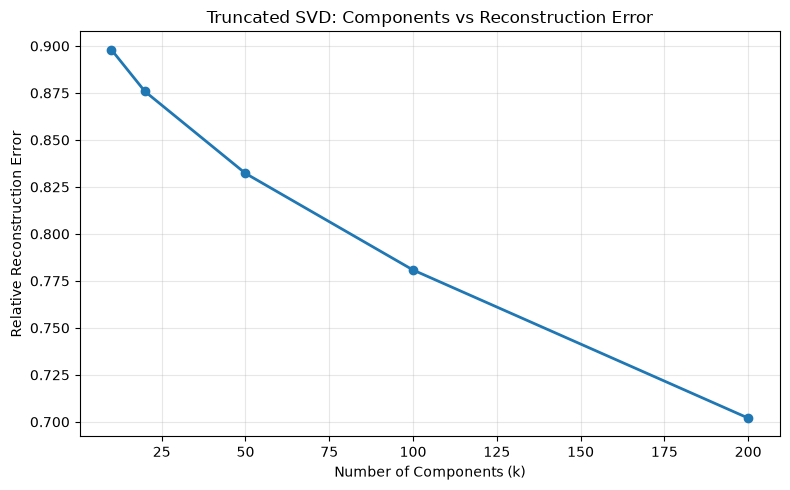

In [49]:
plt.figure(figsize=(8, 5))

plt.plot(
    svd_results["Components"],
    svd_results["Relative Reconstruction Error"],
    marker="o",
    linewidth=2
)

plt.title("Truncated SVD: Components vs Reconstruction Error")
plt.xlabel("Number of Components (k)")
plt.ylabel("Relative Reconstruction Error")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [50]:
svd_results.to_csv(
    output_dir / "svd_experiment_results.csv",
    index=False
)

print("SVD experiment results saved.")

SVD experiment results saved.


ML2 — Results Interpretation
I trained Truncated SVD models using 10, 20, 50, 100, and 200 components. Increasing the number of components reduced reconstruction error from 0.8980 to 0.7020, although training time also increased. I selected 100 components provisionally because it provides a reasonable balance between reconstruction quality and computational cost. The final choice will also consider recommendation performance on held-out purchases.

In [ ]:
from sklearn.preprocessing import normalize

# Using the provisional 100-component model
selected_k = 100

svd_model = svd_models[selected_k]

# Each row represents a product using 100 latent features
product_factors = svd_model.components_.T

# Normalizing vectors for cosine similarity
normalized_products = normalize(product_factors)

print("Product factor matrix shape:", product_factors.shape)
print("Normalized factor matrix shape:", normalized_products.shape)

Product factor matrix shape: (3688, 100)
Normalized factor matrix shape: (3688, 100)


In [ ]:
#creating a function to find similar products
def find_similar_products(product_code, top_n=10):
    if product_code not in product_index:
        return []

    product_position = product_index[product_code]

    # Comparing the selected product with the complete catalogue
    similarity_scores = (
        normalized_products
        @ normalized_products[product_position]
    )

    # Avoid recommending the same product
    similarity_scores[product_position] = -np.inf

    # Selecting products with the highest cosine similarity
    best_positions = np.argsort(similarity_scores)[::-1][:top_n]

    index_to_product = {
        position: code
        for code, position in product_index.items()
    }

    return [
        (index_to_product[position], float(similarity_scores[position]))
        for position in best_positions
    ]

In [53]:
# Find a popular product from the training catalogue
popular_product = (
    matrix_train["StockCode"]
    .value_counts()
    .idxmax()
)

print("Selected product:", popular_product)

similar_items = find_similar_products(
    popular_product,
    top_n=10
)

similarity_results = pd.DataFrame(
    similar_items,
    columns=["StockCode", "Cosine Similarity"]
)

display(similarity_results)

Selected product: 85123A


,StockCode,Cosine Similarity
0,21733,0.683711
1,22804,0.428429
2,71053,0.260459
3,22189,0.231576
4,84877A,0.229315
5,71477,0.215014
6,21765,0.209196
7,21732,0.207159
8,22464,0.206405
9,22224,0.204493


In [ ]:
# Creating product descriptions using training data only
product_names = (
    train_df.dropna(subset=["Description"])
    .groupby("StockCode")["Description"]
    .agg(lambda names: names.mode().iloc[0])
    .to_dict()
)

similarity_results["Description"] = (
    similarity_results["StockCode"]
    .map(product_names)
)

similarity_results = similarity_results[
    ["StockCode", "Description", "Cosine Similarity"]
]

display(similarity_results)

,StockCode,Description,Cosine Similarity
0,21733,RED HANGING HEART T-LIGHT HOLDER,0.683711
1,22804,CANDLEHOLDER PINK HANGING HEART,0.428429
2,71053,WHITE METAL LANTERN,0.260459
3,22189,CREAM HEART CARD HOLDER,0.231576
4,84877A,PINK ROUND COMPACT MIRROR,0.229315
5,71477,COLOUR GLASS. STAR T-LIGHT HOLDER,0.215014
6,21765,HANGING METAL BIRD BATH,0.209196
7,21732,RED HANGING METAL STAR TLIGHT HLDR,0.207159
8,22464,HANGING METAL HEART LANTERN,0.206405
9,22224,WHITE LOVEBIRD LANTERN,0.204493


In [55]:
#customer recommendation function
def recommend_for_customer(customer_id, top_n=10):
    # Check whether the customer exists in training data
    if customer_id not in customer_index:
        return []

    # Find the customer's position in the matrix
    customer_position = customer_index[customer_id]

    # Retrieve products purchased by the customer
    purchased_positions = A.getrow(
        customer_position
    ).indices

    if len(purchased_positions) == 0:
        return []

    # Measure similarity between previously purchased
    # products and all products in the catalogue
    purchased_vectors = normalized_products[purchased_positions]

    scores = (
        purchased_vectors @ normalized_products.T
    ).mean(axis=0)

    # Exclude products already purchased
    scores[purchased_positions] = -np.inf

    # Find the highest-scoring products
    top_positions = np.argsort(scores)[::-1][:top_n]

    return [
        (position, float(scores[position]))
        for position in top_positions
    ]

In [56]:
# Select a customer who has purchased at least one eligible product
customer_activity = np.diff(A.indptr)

sample_position = np.flatnonzero(
    customer_activity > 0
)[0]

index_to_customer = {
    position: customer_id
    for customer_id, position in customer_index.items()
}

sample_customer = index_to_customer[sample_position]

recommendations = recommend_for_customer(
    sample_customer,
    top_n=10
)

index_to_product = {
    position: code
    for code, position in product_index.items()
}

customer_recommendations = pd.DataFrame(
    [
        {
            "StockCode": index_to_product[position],
            "Description": product_names.get(
                index_to_product[position],
                "Unknown product"
            ),
            "Recommendation Score": score
        }
        for position, score in recommendations
    ]
)

print("Recommendations for an anonymized sample customer:")
display(customer_recommendations)

Recommendations for an anonymized sample customer:


,StockCode,Description,Recommendation Score
0,22135,LADLE LOVE HEART PINK,0.131938
1,22131,FOOD CONTAINER SET 3 LOVE HEART,0.129163
2,84050,PINK HEART SHAPE EGG FRYING PAN,0.126580
3,22133,PINK LOVE HEART SHAPE CUP,0.115349
4,22134,LADLE LOVE HEART RED,0.113498
5,22132,RED LOVE HEART SHAPE CUP,0.108213
6,22203,MILK PAN RED RETROSPOT,0.107288
7,23339,EGG FRYING PAN BLUE,0.101547
8,22347,PIZZA SLICE DISH,0.099445
9,22196,SMALL HEART MEASURING SPOONS,0.095936


In [57]:
recommended_positions = [
    position for position, score in recommendations
]

previously_purchased = set(
    A.getrow(sample_position).indices
)

assert len(recommended_positions) <= 10
assert len(recommended_positions) == len(set(recommended_positions))

assert all(
    position not in previously_purchased
    for position in recommended_positions
)

print("Customer recommendation validation passed!")

Customer recommendation validation passed!


In [58]:
# Keeping held-out purchases that can be represented by our model
evaluation_df = heldout_df.loc[
    heldout_df["Customer ID"].isin(customer_index)
    & heldout_df["StockCode"].isin(product_index)
].copy()

print("Original held-out pairs:", len(heldout_df))
print("Evaluable held-out pairs:", len(evaluation_df))

print(
    "Customers with evaluable purchases:",
    evaluation_df["Customer ID"].nunique()
)

Original held-out pairs: 49423
Evaluable held-out pairs: 44727
Customers with evaluable purchases: 1913


In [59]:
# Each customer has a set of products purchased in the test period
customer_ground_truth = (
    evaluation_df.groupby("Customer ID")["StockCode"]
    .agg(set)
    .to_dict()
)

print("Customers to evaluate:", len(customer_ground_truth))

Customers to evaluate: 1913


In [60]:
# Ranking products by number of distinct training customers
best_seller_ranking = (
    matrix_train["StockCode"]
    .value_counts()
    .index
    .tolist()
)

def recommend_best_sellers(customer_id, top_n=10):
    if customer_id not in customer_index:
        return []

    customer_position = customer_index[customer_id]

    purchased_positions = set(
        A.getrow(customer_position).indices
    )

    purchased_codes = {
        code
        for code, position in product_index.items()
        if position in purchased_positions
    }

    suggestions = [
        code
        for code in best_seller_ranking
        if code not in purchased_codes
    ]

    return suggestions[:top_n]

In [ ]:
#Calculating Hit Rate@10
import time

svd_hits = 0
baseline_hits = 0

evaluation_start = time.perf_counter()

for customer_id, actual_products in customer_ground_truth.items():

    # Personalized recommendations
    svd_recommendations = recommend_for_customer(
        customer_id,
        top_n=10
    )

    svd_product_codes = {
        index_to_product[position]
        for position, score in svd_recommendations
    }

    # Baseline recommendations
    baseline_products = set(
        recommend_best_sellers(customer_id, top_n=10)
    )

    # A hit occurs if at least one actual future purchase
    # appears in the recommendation list
    if actual_products.intersection(svd_product_codes):
        svd_hits += 1

    if actual_products.intersection(baseline_products):
        baseline_hits += 1

evaluation_seconds = time.perf_counter() - evaluation_start

total_customers = len(customer_ground_truth)

svd_hit_rate = svd_hits / total_customers
baseline_hit_rate = baseline_hits / total_customers

print(f"SVD Hit Rate@10: {svd_hit_rate:.2%}")
print(f"Baseline Hit Rate@10: {baseline_hit_rate:.2%}")
print(f"Evaluation time: {evaluation_seconds:.2f} seconds")

SVD Hit Rate@10: 25.88%
Baseline Hit Rate@10: 26.87%
Evaluation time: 3.99 seconds


In [62]:
ml4_results = pd.DataFrame({
    "Model": [
        "Truncated SVD",
        "Best-Seller Baseline"
    ],
    "Hit Rate@10 (%)": [
        round(svd_hit_rate * 100, 2),
        round(baseline_hit_rate * 100, 2)
    ],
    "Customers Evaluated": [
        total_customers,
        total_customers
    ],
    "Customers with Hits": [
        svd_hits,
        baseline_hits
    ]
})

display(ml4_results)

ml4_results.to_csv(
    output_dir / "model_evaluation.csv",
    index=False
)

,Model,Hit Rate@10 (%),Customers Evaluated,Customers with Hits
0,Truncated SVD,25.88,1913,495
1,Best-Seller Baseline,26.87,1913,514


In [63]:
#comparing recommendation accuracy across k values
from sklearn.preprocessing import normalize

k_evaluation_results = []

for k, model in svd_models.items():

    product_vectors = normalize(model.components_.T)

    customer_hits = 0

    start = time.perf_counter()

    for customer_id, actual_products in customer_ground_truth.items():

        customer_position = customer_index[customer_id]

        purchased = A.getrow(customer_position).indices

        if len(purchased) == 0:
            continue

        scores = (
            product_vectors[purchased]
            @ product_vectors.T
        ).mean(axis=0)

        scores[purchased] = -np.inf

        best_positions = np.argsort(scores)[::-1][:10]

        recommended_codes = {
            index_to_product[pos]
            for pos in best_positions
        }

        if actual_products.intersection(recommended_codes):
            customer_hits += 1

    elapsed = time.perf_counter() - start

    hit_rate = customer_hits / len(customer_ground_truth)

    k_evaluation_results.append({
        "Components": k,
        "Hit Rate@10 (%)": round(hit_rate * 100, 2),
        "Customers with Hits": customer_hits,
        "Evaluation Time (s)": round(elapsed, 2)
    })

k_performance = pd.DataFrame(k_evaluation_results)

display(k_performance)

,Components,Hit Rate@10 (%),Customers with Hits,Evaluation Time (s)
0,10,16.00,306,3.45
1,20,19.81,379,3.53
2,50,23.16,443,3.11
3,100,25.88,495,3.47
4,200,23.89,457,3.25


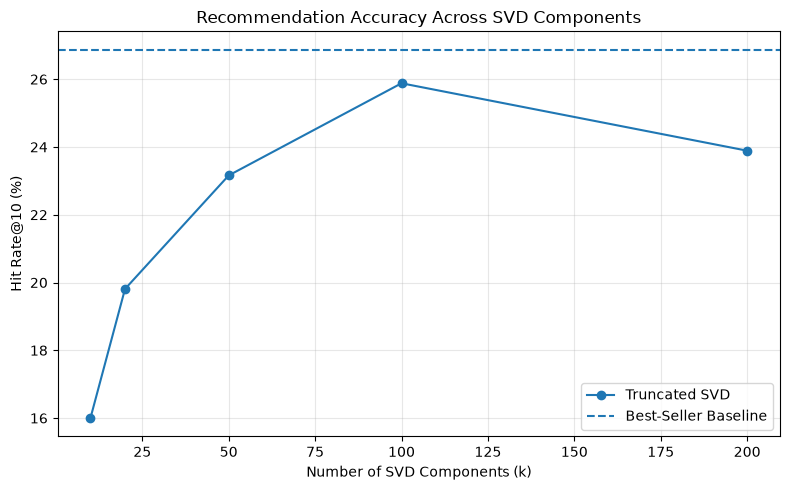

In [64]:
#Visually comparing them
plt.figure(figsize=(8, 5))

plt.plot(
    k_performance["Components"],
    k_performance["Hit Rate@10 (%)"],
    marker="o",
    label="Truncated SVD"
)

plt.axhline(
    y=baseline_hit_rate * 100,
    linestyle="--",
    label="Best-Seller Baseline"
)

plt.xlabel("Number of SVD Components (k)")
plt.ylabel("Hit Rate@10 (%)")
plt.title("Recommendation Accuracy Across SVD Components")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

ML4 — Evaluation Findings
The Truncated SVD recommender achieved a Hit Rate@10 of 25.88%, compared with 26.87% for the best-seller baseline, across 1,913 evaluable customers. The baseline identified relevant future purchases for 19 more customers. These results suggest that product popularity is a strong predictor in this dataset and that the current SVD recommendation strategy does not yet provide a measurable improvement. Further experiments will examine component count and recommendation scoring.

In [ ]:
import time
import tracemalloc
from sklearn.decomposition import PCA

selected_k = 100

tracemalloc.start()
start_time = time.perf_counter()

pca_model = PCA(
    n_components=selected_k,
    svd_solver="arpack",
    random_state=42
)

pca_customer_factors = pca_model.fit_transform(A)

pca_fit_time = time.perf_counter() - start_time

_, pca_peak_memory = tracemalloc.get_traced_memory()
tracemalloc.stop()

print(f"PCA fit time: {pca_fit_time:.2f} seconds")
print(f"PCA traced peak memory: {pca_peak_memory / 1024**2:.2f} MB")
print(
    "PCA explained variance:",
    f"{pca_model.explained_variance_ratio_.sum() * 100:.2f}%"
)

ML5 — Compare PCA and Truncated SVD

In [ ]:
#Fit PCA and measuring training time
import time
import tracemalloc
from sklearn.decomposition import PCA

selected_k = 100

tracemalloc.start()
start_time = time.perf_counter()

pca_model = PCA(
    n_components=selected_k,
    svd_solver="arpack",
    random_state=42
)

pca_customer_factors = pca_model.fit_transform(A)

pca_fit_time = time.perf_counter() - start_time

_, pca_peak_memory = tracemalloc.get_traced_memory()
tracemalloc.stop()

print(f"PCA fit time: {pca_fit_time:.2f} seconds")
print(f"PCA traced peak memory: {pca_peak_memory / 1024**2:.2f} MB")
print(
    "PCA explained variance:",
    f"{pca_model.explained_variance_ratio_.sum() * 100:.2f}%"
)

PCA fit time: 0.48 seconds
PCA traced peak memory: 12.76 MB
PCA explained variance: 36.17%


In [ ]:
#Evaluating PCA recommendation
pca_products = normalize(pca_model.components_.T)

pca_hits = 0
start_time = time.perf_counter()

for customer_id, actual_products in customer_ground_truth.items():

    customer_position = customer_index[customer_id]
    purchased = A.getrow(customer_position).indices

    if len(purchased) == 0:
        continue

    scores = (
        pca_products[purchased]
        @ pca_products.T
    ).mean(axis=0)

    scores[purchased] = -np.inf

    top_positions = np.argsort(scores)[::-1][:10]

    predicted_products = {
        index_to_product[position]
        for position in top_positions
    }

    if actual_products.intersection(predicted_products):
        pca_hits += 1

pca_evaluation_time = time.perf_counter() - start_time

pca_hit_rate = pca_hits / len(customer_ground_truth)

print(f"PCA Hit Rate@10: {pca_hit_rate:.2%}")
print(f"PCA successful customers: {pca_hits}")
print(f"PCA evaluation time: {pca_evaluation_time:.2f} seconds")

PCA Hit Rate@10: 24.83%
PCA successful customers: 475
PCA evaluation time: 4.01 seconds


In [67]:
#building a comparison table
svd_model = svd_models[selected_k]

svd_fit_time = float(
    svd_results.loc[
        svd_results["Components"] == selected_k,
        "Fit Time (seconds)"
    ].iloc[0]
)

factor_size_mb = (
    (A.shape[0] + A.shape[1])
    * selected_k
    * np.dtype(np.float32).itemsize
    / 1024**2
)

comparison = pd.DataFrame({
    "Measure": [
        "Components (k)",
        "Fit time (seconds)",
        "Stored factor size (MB, float32 estimate)",
        "Explained variance (%)",
        "Hit Rate@10 (%)",
        "Baseline Hit Rate@10 (%)"
    ],
    "PCA": [
        selected_k,
        round(pca_fit_time, 2),
        round(factor_size_mb, 2),
        round(pca_model.explained_variance_ratio_.sum() * 100, 2),
        round(pca_hit_rate * 100, 2),
        round(baseline_hit_rate * 100, 2)
    ],
    "Truncated SVD": [
        selected_k,
        round(svd_fit_time, 2),
        round(factor_size_mb, 2),
        round(svd_model.explained_variance_ratio_.sum() * 100, 2),
        round(svd_hit_rate * 100, 2),
        round(baseline_hit_rate * 100, 2)
    ]
})

display(comparison)

,Measure,PCA,Truncated SVD
0,Components (k),100.000000,100.000000
1,Fit time (seconds),0.480000,0.310000
2,"Stored factor size (MB, float32 estimate)",3.500000,3.500000
3,Explained variance (%),36.169998,36.049999
4,Hit Rate@10 (%),24.830000,25.880000
5,Baseline Hit Rate@10 (%),26.870000,26.870000


In [68]:
#measuring PCA and SVD peak memory consistently
import tracemalloc
import time
from sklearn.decomposition import PCA, TruncatedSVD

def measure_model(model, matrix):
    tracemalloc.start()
    start = time.perf_counter()

    model.fit(matrix)

    elapsed = time.perf_counter() - start
    _, peak = tracemalloc.get_traced_memory()

    tracemalloc.stop()

    return elapsed, peak / (1024 ** 2)


pca_time, pca_memory = measure_model(
    PCA(n_components=100, svd_solver="arpack", random_state=42),
    A
)

svd_time, svd_memory = measure_model(
    TruncatedSVD(n_components=100, n_iter=7, random_state=42),
    A
)

print(f"PCA: {pca_time:.3f}s, {pca_memory:.2f} MB")
print(f"SVD: {svd_time:.3f}s, {svd_memory:.2f} MB")

PCA: 0.472s, 12.76 MB
SVD: 0.320s, 8.51 MB


In [ ]:
#Examining what component 1 represents
def inspect_first_component(model, method_name):
    weights = model.components_[0]

    # Strongest absolute loadings
    top_positions = np.argsort(
        np.abs(weights)
    )[::-1][:10]

    component_table = pd.DataFrame({
        "Product": [
            product_names.get(index_to_product[pos], "Unknown")
            for pos in top_positions
        ],
        "Component Weight": weights[top_positions]
    })

    print(f"\n{method_name} — Component 1")
    display(component_table)


inspect_first_component(pca_model, "PCA")
inspect_first_component(svd_model, "Truncated SVD")


PCA — Component 1


,Product,Component Weight
0,PACK OF 72 RETROSPOT CAKE CASES,0.078384
1,LUNCH BAG RED RETROSPOT,0.073682
2,WHITE HANGING HEART T-LIGHT HOLDER,0.070035
3,LUNCH BAG SPACEBOY DESIGN,0.068674
4,JUMBO BAG RED RETROSPOT,0.067875
5,60 TEATIME FAIRY CAKE CASES,0.066055
6,LUNCH BAG PINK POLKADOT,0.065400
7,SET/20 RED RETROSPOT PAPER NAPKINS,0.064727
8,LUNCH BAG CARS BLUE,0.063998
9,LUNCH BAG BLACK SKULL.,0.062455



Truncated SVD — Component 1


,Product,Component Weight
0,WHITE HANGING HEART T-LIGHT HOLDER,0.098590
1,PACK OF 72 RETROSPOT CAKE CASES,0.088671
2,REGENCY CAKESTAND 3 TIER,0.085240
3,JUMBO BAG RED RETROSPOT,0.075976
4,LUNCH BAG RED RETROSPOT,0.075850
5,60 TEATIME FAIRY CAKE CASES,0.070575
6,LUNCH BAG SPACEBOY DESIGN,0.069960
7,SET/20 RED RETROSPOT PAPER NAPKINS,0.068960
8,BAKING SET 9 PIECE RETROSPOT,0.068874
9,PARTY BUNTING,0.067491


ML5 — PCA vs Truncated SVD Comparison
Both methods were evaluated using 100 components and the same training matrix. Truncated SVD achieved a Hit Rate@10 of 25.88%, compared with 24.83% for PCA. SVD also required less fitting time in the recorded experiment. Although PCA explained slightly more variance, SVD produced better recommendations under the selected cosine-similarity scoring strategy. Therefore, I retained Truncated SVD as the primary model. However, neither model outperformed the best-seller baseline, indicating that further improvement is necessary before deployment.

ML6 — Customer Segmentation Using SVD and K-Means

In [71]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import normalize

# Use the selected SVD model
selected_k = 100
svd_model = svd_models[selected_k]

# Transform customers into the reduced feature space
customer_features = svd_model.transform(A)

print("Original matrix shape:", A.shape)
print("Reduced customer features:", customer_features.shape)

Original matrix shape: (5474, 3688)
Reduced customer features: (5474, 100)


In [ ]:
# Normalizing to focus clustering on purchasing patterns
# rather than primarily on the number of purchases
customer_features_scaled = normalize(customer_features)

print("Normalized shape:", customer_features_scaled.shape)

print(
    "Number of customers:",
    len(customer_features_scaled)
)

Normalized shape: (5474, 100)
Number of customers: 5474


In [73]:
#Creating five customer clusters
# Grouping customers based on their SVD representations
kmeans_model = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans_model.fit_predict(
    customer_features_scaled
)

cluster_sizes = (
    pd.Series(cluster_labels)
    .value_counts()
    .sort_index()
)

print("Number of clusters:", len(cluster_sizes))
print("\nCustomers per cluster:")

display(cluster_sizes.rename("Customer Count"))

Number of clusters: 5

Customers per cluster:


0    1601
1     947
2     442
3    1337
4    1147
Name: Customer Count, dtype: int64

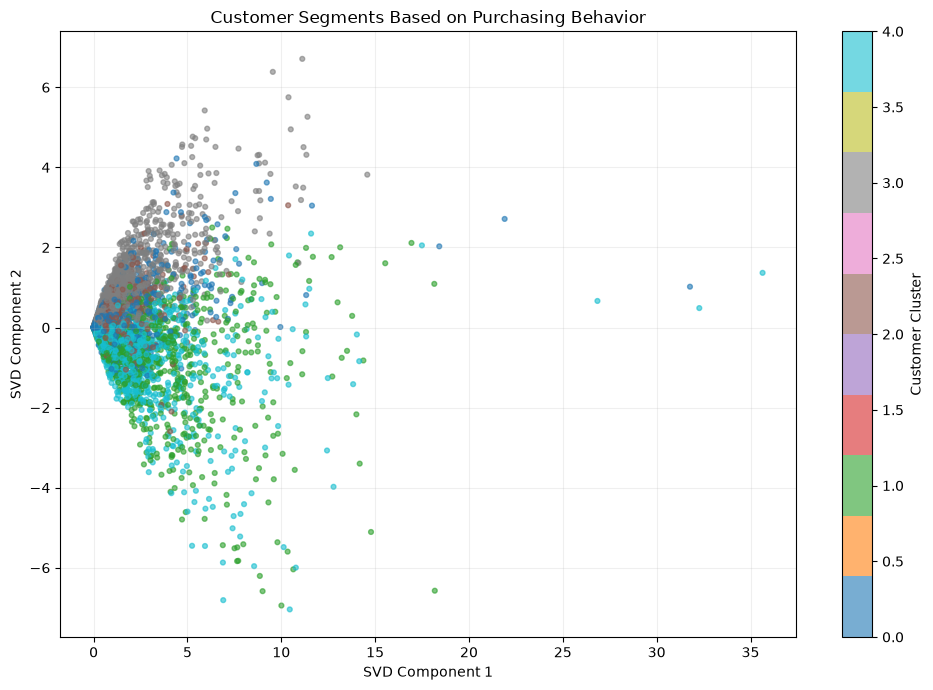

In [74]:
#creating a 2D map
import matplotlib.pyplot as plt

customer_map = pd.DataFrame({
    "Component 1": customer_features[:, 0],
    "Component 2": customer_features[:, 1],
    "Cluster": cluster_labels
})

plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    customer_map["Component 1"],
    customer_map["Component 2"],
    c=customer_map["Cluster"],
    cmap="tab10",
    s=12,
    alpha=0.6
)

plt.title("Customer Segments Based on Purchasing Behavior")
plt.xlabel("SVD Component 1")
plt.ylabel("SVD Component 2")

plt.colorbar(scatter, label="Customer Cluster")

plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    output_dir / "customer_segments.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

ML6: Identify what each cluster purchases

In [ ]:
# Associating each matrix customer row with its cluster
cluster_lookup = pd.DataFrame({
    "Customer ID": list(customer_index.keys()),
    "Cluster": cluster_labels
})

# Combine cluster information with training transactions
cluster_transactions = train_df.merge(
    cluster_lookup,
    on="Customer ID",
    how="inner",
    validate="many_to_one"
)

print("Transactions assigned to clusters:", len(cluster_transactions))
print("Customers represented:",
      cluster_transactions["Customer ID"].nunique())

Transactions assigned to clusters: 684098
Customers represented: 5474


In [ ]:
# Counting distinct customers buying each product within each cluster
product_preferences = (
    cluster_transactions
    .groupby(["Cluster", "StockCode", "Description"])["Customer ID"]
    .nunique()
    .reset_index(name="Customer Count")
)

# Sort products by the number of customers purchasing them
product_preferences = product_preferences.sort_values(
    ["Cluster", "Customer Count"],
    ascending=[True, False]
)

top_cluster_products = (
    product_preferences
    .groupby("Cluster")
    .head(5)
)

for cluster_id, products in top_cluster_products.groupby("Cluster"):
    print(f"\nCluster {cluster_id} — Top Products")
    display(products[["Description", "Customer Count"]])


Cluster 0 — Top Products


,Description,Customer Count
3245,60 TEATIME FAIRY CAKE CASES,222
526,STRAWBERRY CERAMIC TRINKET BOX,215
1183,PACK OF 60 PINK PAISLEY CAKE CASES,184
355,REX CASH+CARRY JUMBO SHOPPER,172
507,PACK OF 72 RETROSPOT CAKE CASES,160



Cluster 1 — Top Products


,Description,Customer Count
8982,JUMBO BAG RED RETROSPOT,504
6236,LUNCH BAG SPACEBOY DESIGN,452
4771,LUNCH BAG CARS BLUE,436
4770,LUNCH BAG BLACK SKULL.,424
4767,LUNCH BAG RED RETROSPOT,364



Cluster 2 — Top Products


,Description,Customer Count
10691,REGENCY CAKESTAND 3 TIER,393
10986,ROSES REGENCY TEACUP AND SAUCER,237
10982,GREEN REGENCY TEACUP AND SAUCER,230
10984,PINK REGENCY TEACUP AND SAUCER,192
11558,SET OF 3 REGENCY CAKE TINS,108



Cluster 3 — Top Products


,Description,Customer Count
17137,WHITE HANGING HEART T-LIGHT HOLDER,777
14570,HEART OF WICKER SMALL,422
14571,HEART OF WICKER LARGE,416
16089,ASSORTED COLOUR BIRD ORNAMENT,398
14560,NATURAL SLATE HEART CHALKBOARD,358



Cluster 4 — Top Products


,Description,Customer Count
18509,VINTAGE SNAP CARDS,409
18803,BAKING SET 9 PIECE RETROSPOT,381
18510,VINTAGE HEADS AND TAILS CARD GAME,366
18815,FELTCRAFT 6 FLOWER FRIENDS,308
19310,WOODEN SCHOOL COLOURING SET,293


In [77]:
# One country per customer, using their most frequent recorded country
customer_countries = (
    cluster_transactions
    .groupby(["Cluster", "Customer ID"])["Country"]
    .agg(lambda values: values.mode().iloc[0])
    .reset_index()
)

country_summary = (
    customer_countries
    .groupby(["Cluster", "Country"])
    .size()
    .reset_index(name="Customers")
    .sort_values(
        ["Cluster", "Customers"],
        ascending=[True, False]
    )
)

for cluster_id, countries in country_summary.groupby("Cluster"):
    print(f"\nCluster {cluster_id} — Top Countries")
    display(countries[["Country", "Customers"]].head(3))


Cluster 0 — Top Countries


,Country,Customers
27,United Kingdom,1465
11,Germany,28
10,France,20



Cluster 1 — Top Countries


,Country,Customers
49,United Kingdom,825
38,Germany,30
37,France,24



Cluster 2 — Top Countries


,Country,Customers
69,United Kingdom,406
55,France,5
67,Switzerland,4



Cluster 3 — Top Countries


,Country,Customers
87,United Kingdom,1302
75,France,5
84,Spain,5



Cluster 4 — Top Countries


,Country,Customers
114,United Kingdom,999
99,Germany,32
98,France,30


In [78]:
# Count distinct purchased products for each customer
customer_activity = (
    cluster_transactions
    .groupby(["Cluster", "Customer ID"])["StockCode"]
    .nunique()
    .reset_index(name="Unique Products")
)

activity_summary = (
    customer_activity
    .groupby("Cluster")["Unique Products"]
    .agg(["mean", "median", "max"])
    .round(2)
)

display(activity_summary)

,mean,median,max
Cluster,,,
0,45.03,22.0,2005
1,119.05,78.0,862
2,54.94,36.5,415
3,72.16,45.0,776
4,97.78,55.0,2355


In [79]:
#Create the segment dictionary
segment_names = {
    0: "Everyday Gifts & Baking",
    1: "Bags & Accessories",
    2: "Regency Tea & Tableware",
    3: "Home Decor & Heart Gifts",
    4: "Creative Gifts & Activities"
}

# Add descriptive labels to the customer map
customer_map["Segment"] = customer_map["Cluster"].map(
    segment_names
)

print("Segment names successfully assigned.")

display(
    customer_map["Segment"]
    .value_counts()
)

Segment names successfully assigned.


Segment
Everyday Gifts & Baking        1601
Home Decor & Heart Gifts       1337
Creative Gifts & Activities    1147
Bags & Accessories              947
Regency Tea & Tableware         442
Name: count, dtype: int64

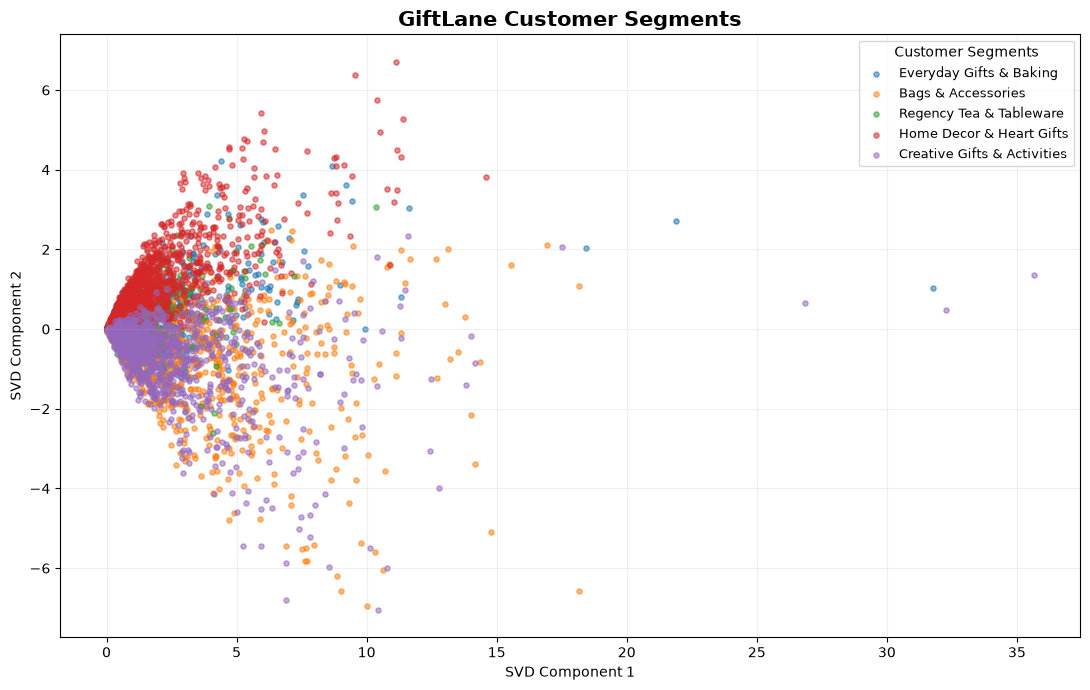

In [80]:
#creating the final customer segmentation map
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 7))

for cluster_id, segment_name in segment_names.items():

    subset = customer_map[
        customer_map["Cluster"] == cluster_id
    ]

    ax.scatter(
        subset["Component 1"],
        subset["Component 2"],
        label=segment_name,
        s=14,
        alpha=0.55
    )

ax.set_title(
    "GiftLane Customer Segments",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("SVD Component 1")
ax.set_ylabel("SVD Component 2")

ax.legend(
    title="Customer Segments",
    loc="upper right",
    fontsize=9
)

ax.grid(alpha=0.2)

plt.tight_layout()

plt.savefig(
    output_dir / "customer_segments_final.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:
#Creating and saving a businness-friendly table
segment_summary = pd.DataFrame({
    "Cluster": [0, 1, 2, 3, 4],
    "Segment": [segment_names[i] for i in range(5)],
    "Customers": [1601, 947, 442, 1337, 1147],
    "Avg Unique Products": [
        45.03, 119.05, 54.94, 72.16, 97.78
    ],
    "Primary Country": ["United Kingdom"] * 5
})

display(segment_summary)

segment_summary.to_csv(
    output_dir / "customer_segment_summary.csv",
    index=False
)

print("Customer segment summary saved.")

,Cluster,Segment,Customers,Avg Unique Products,Primary Country
0,0,Everyday Gifts & Baking,1601,45.03,United Kingdom
1,1,Bags & Accessories,947,119.05,United Kingdom
2,2,Regency Tea & Tableware,442,54.94,United Kingdom
3,3,Home Decor & Heart Gifts,1337,72.16,United Kingdom
4,4,Creative Gifts & Activities,1147,97.78,United Kingdom


Customer segment summary saved.


ML6 — Customer Segmentation Findings
I applied K-Means clustering to the normalized 100-dimensional customer representations obtained through Truncated SVD. The model divided 5,474 customers into five groups based on similarities in their purchasing patterns.
The clusters showed distinct product preferences, including baking supplies, bags and accessories, Regency tableware, home decorations, and creative gifts. Customer purchasing variety also differed between groups, with average distinct product counts ranging from 45.03 to 119.05.
The United Kingdom was the dominant country across all five segments. Although the clusters overlap in the two-dimensional visualization, the segmentation provides a starting point for developing product-specific marketing campaigns.

In [82]:
#saving matrix index mappings
import json

# Convert matrix positions into product codes
product_mapping = {
    str(position): str(code)
    for code, position in product_index.items()
}

# Save product positions for the recommender
with open(
    output_dir / "product_index.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(product_mapping, file, indent=2)

print("Product mapping saved.")
print("Products mapped:", len(product_mapping))

Product mapping saved.
Products mapped: 3688


In [83]:
customer_mapping = {
    str(position): str(customer_id)
    for customer_id, position in customer_index.items()
}

private_dir = project_dir / "data" / "processed"
private_dir.mkdir(parents=True, exist_ok=True)

with open(
    private_dir / "customer_index.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(customer_mapping, file, indent=2)

print("Private customer mapping saved.")

Private customer mapping saved.


In [84]:
# Saving PCA vs SVD comparison
comparison.to_csv(
    output_dir / "pca_svd_comparison.csv",
    index=False
)

# Save SVD component performance
k_performance.to_csv(
    output_dir / "k_performance.csv",
    index=False
)

print("Additional evaluation files saved successfully!")

Additional evaluation files saved successfully!
